# CDC HDP-proxy · фиксированные baseline, вложенный подбор и итоговое обучение

**В этой рабочей папке начинайте с 02:** подготовленный Parquet и аудит уже есть. 01 нужен только при намеренной пересборке когорты; повторная запись Parquet может изменить контрольную сумму и сделать существующие кэши несовместимыми. На каждом фолде модели видят остальные четыре фолда из объединённых 2023+2024 и предсказывают только отложенные записи. Обучение не запускается при создании ноутбуков.

Предзаданные ориентиры: частота метки, линейная логистика, логистика со сплайнами возраста/BMI и категориями числа прошлых живорождений, неглубокий HistGradientBoosting, CatBoost и LightGBM с фиксированными параметрами. Затем **в этом же ноутбуке** выполняются вложенный подбор на общих фолдах и отдельный пятифолдовый выбор параметров для итогового обучения на всей когорте. Все основные бустинги получают одинаковые признаки, включая `NaN` и явные маски; у CatBoost здесь нет категориальных входов, поэтому его преимущество обработки категорий не предполагается заранее. Для отсутствующего BMI, числа прошлых живорождений и числа других исходов предыдущих беременностей есть явные маски. Логистическая импутация обучается только на train; градиентный бустинг получает NaN и те же маски. Обязательные возраст и три двоичных фактора анамнеза проверяются без импутации. Нет хронической АГ и курения в признаках. Классы не перебалансируются. Коэффициенты штрафной логистики не следует интерпретировать как скорректированные OR; для объяснения используются частоты, графики и отложенная перестановочная важность. Коды `MRACE6` расшифровываются по руководству NCHS как социальные категории регистрации, а не биологический механизм. ВРТ и демография исследуются отдельно на временном тесте в 06. Пять фолдов дают **распределение метрик, не доверительный интервал и не проверку будущего года**. Уже сохранённые фиксированные результаты сверяются и используются повторно. Подробности — в [MODEL_BENCHMARKS.md](MODEL_BENCHMARKS.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/data/preeclampsia_cdc.py").exists())
sys.path.insert(0, str(ROOT))
from src.progress import tqdm
plt.rcParams.update({"figure.figsize": (8, 4.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2})
BLUE, ORANGE, GREY = "#255B8B", "#D17A31", "#666D78"
MODEL_PALETTE = [("logistic_spline", BLUE), ("hist_gb", ORANGE),
                 ("catboost", "#287D69"), ("lightgbm", "#8062A5")]
RACE6 = {1:"White",2:"Black",3:"AIAN",4:"Asian",5:"NHOPI",6:"Multiple"}  # NCHS MRACE6; social reporting categories
from src.data.preeclampsia_cdc import OUT, FEATURES
from src.training.preeclampsia_cdc import fit_folds, MODEL_NAMES, HGB_PARAMS, CATBOOST_PARAMS, LIGHTGBM_PARAMS

In [2]:
import shutil
import psutil
from src.training.preeclampsia_cdc import run_fingerprint
from src.training.preeclampsia_cdc_tuning import runtime_versions
from src.training.preeclampsia_cdc_nested import NESTED_DIR, nested_fingerprint
from src.training.preeclampsia_cdc_final import FINAL_DIR, final_fingerprint
source_path = OUT / "eligible_all_2023_2024.parquet"
assert source_path.exists(), "Сначала запустите 01_prepare_data.ipynb"
audit = json.loads((OUT / "audit.json").read_text())
fold_table = pd.read_csv(OUT / "folds_all.csv")
assert len(fold_table) == 10 and fold_table.groupby("year").fold.nunique().eq(5).all()
assert int(fold_table.rows.sum()) == sum(x["eligible_singleton_rows"] for x in audit["year_checks"].values())
assert int(fold_table.events.sum()) == sum(x["eligible_singleton_events"] for x in audit["year_checks"].values())
assert not set(FEATURES) & {"source_year", "fold", "target_hdp_proxy", "rf_ghype", "rf_ehype", "oegest_comb"}
for manifest_name in ("fold_run.json", "temporal_run.json"):
    manifest_path = OUT / manifest_name
    if manifest_path.exists():
        assert json.loads(manifest_path.read_text())["fingerprint"] == run_fingerprint(), f"Устаревший кэш: {manifest_name}"
for search_dir, expected_fingerprint in ((NESTED_DIR, nested_fingerprint()), (FINAL_DIR, final_fingerprint())):
    manifest_path = search_dir / "manifest.json"
    if manifest_path.exists():
        assert json.loads(manifest_path.read_text())["fingerprint"] == expected_fingerprint, f"Устаревший поиск: {search_dir}"
free_gb = shutil.disk_usage(OUT).free / 1e9
memory_gb = psutil.virtual_memory().total / 1e9
available_memory_gb = psutil.virtual_memory().available / 1e9
print(f"Данные: {fold_table.rows.sum():,} строк, {fold_table.events.sum():,} событий; свободный диск: {free_gb:.1f} ГБ; ОЗУ: {memory_gb:.1f} ГБ, сейчас доступно {available_memory_gb:.1f} ГБ")
print("Версии:", runtime_versions())
print("Признаки:", FEATURES)
print("Модели:", MODEL_NAMES)
print("HGB:", HGB_PARAMS)
print("CatBoost:", CATBOOST_PARAMS)
print("LightGBM:", LIGHTGBM_PARAMS)
if free_gb < 10:
    print("ВНИМАНИЕ: для промежуточных прогнозов подбора может не хватить места на диске")
if memory_gb < 16:
    print("ВНИМАНИЕ: полный поиск на миллионах строк может исчерпать ОЗУ")
if available_memory_gb < 8:
    print("ВНИМАНИЕ: перед полным поиском освободите ОЗУ; доступная память сейчас низкая")

Данные: 6,763,850 строк, 712,918 событий; свободный диск: 150.4 ГБ; ОЗУ: 25.8 ГБ, сейчас доступно 9.6 ГБ
Версии: {'python': '3.11.9', 'numpy': '2.4.6', 'pandas': '2.3.3', 'scipy': '1.17.1', 'scikit-learn': '1.9.1', 'catboost': '1.2.10', 'lightgbm': '4.7.0', 'pyarrow': '25.0.1', 'joblib': '1.6.0'}
Признаки: ['mager', 'bmi', 'prior_live_birth_count_cat', 'priorterm', 'rf_pdiab', 'rf_ppterm', 'rf_cesar', 'bmi_missing', 'prior_live_birth_count_missing', 'priorterm_missing']
Модели: ['prevalence', 'logistic', 'logistic_spline', 'hist_gb', 'catboost', 'lightgbm']
HGB: {'max_leaf_nodes': 15, 'learning_rate': 0.07, 'min_samples_leaf': 200, 'l2_regularization': 10.0, 'max_bins': 63, 'early_stopping': False, 'warm_start': True, 'random_state': 20261001}
CatBoost: {'iterations': 300, 'depth': 5, 'learning_rate': 0.05, 'l2_leaf_reg': 8.0, 'loss_function': 'Logloss', 'random_seed': 20261001, 'thread_count': -1, 'allow_writing_files': False, 'task_type': 'CPU'}
LightGBM: {'n_estimators': 300, 'learn

## Обучение и OOF-прогнозы всех записей

In [3]:
fold_metrics = fit_folds(resume=True)
display(fold_metrics.round(4))

Loading audited pooled cohort...


Pooled CV:   0%|          | 0/5 [00:00<?, ?fold/s]

,fold,model,n,events,auroc,auprc,brier,log_loss,mean_prediction,prevalence
0,0,prevalence,1353273,142657,0.5000,0.1054,0.0943,0.3368,0.1054,0.1054
1,0,logistic,1353273,142657,0.6570,0.1894,0.0912,0.3218,0.1054,0.1054
2,0,logistic_spline,1353273,142657,0.6637,0.1921,0.0909,0.3204,0.1055,0.1054
3,0,hist_gb,1353273,142657,0.6658,0.1932,0.0908,0.3199,0.1054,0.1054
4,0,catboost,1353273,142657,0.6659,0.1940,0.0908,0.3198,0.1054,0.1054
5,0,lightgbm,1353273,142657,0.6660,0.1936,0.0908,0.3198,0.1054,0.1054
6,1,prevalence,1354005,142970,0.5000,0.1056,0.0944,0.3372,0.1054,0.1056
7,1,logistic,1354005,142970,0.6570,0.1887,0.0914,0.3223,0.1053,0.1056
8,1,logistic_spline,1354005,142970,0.6631,0.1915,0.0911,0.3209,0.1054,0.1056
9,1,hist_gb,1354005,142970,0.6651,0.1926,0.0910,0.3204,0.1054,0.1056


## Покрытие фолдов и разброс качества фиксированных моделей

,fold,n,events,prevalence
0,0,1353273,142657,0.105416
6,1,1354005,142970,0.105590
12,2,1352650,142580,0.105408
18,3,1351623,142420,0.105370
24,4,1352299,142291,0.105222


auroc                               auprc           \
                    mean      std      min      max     mean      std   
model                                                                   
catboost         0.66551  0.00050  0.66495  0.66613  0.19336  0.00068   
hist_gb          0.66539  0.00053  0.66474  0.66608  0.19269  0.00054   
lightgbm         0.66557  0.00052  0.66494  0.66620  0.19305  0.00054   
logistic         0.65699  0.00027  0.65668  0.65742  0.18879  0.00058   
logistic_spline  0.66342  0.00050  0.66279  0.66407  0.19155  0.00056   
prevalence       0.50000  0.00000  0.50000  0.50000  0.10540  0.00013   

                                     brier                             \
                     min      max     mean      std      min      max   
model                                                                   
catboost         0.19235  0.19405  0.09081  0.00011  0.09066  0.09097   
hist_gb          0.19185  0.19324  0.09083  0.00011  0.09067  0.09099   
lightgbm         0.19221  0.19365  0.09081  0.00011  0.09066  0.09097   
logistic         0.18816  0.18939  0.09120  0.00010  0.09107  0.09136   
logistic_spline  0.19072  0.19208  0.09092  0.00011  0.09077  0.09108   
prevalence       0.10522  0.10559  0.09429  0.00010  0.09415  0.09444   

                log_loss                             
                    mean      std      min      max  
model                                                
catboost         0.31994  0.00032  0.31951  0.32041  
hist_gb          0.31999  0.00032  0.31954  0.32045  
lightgbm         0.31994  0.00032  0.31950  0.32040  
logistic         0.32184  0.00029  0.32148  0.32228  
logistic_spline  0.32042  0.00032  0.31998  0.32089  
prevalence       0.33679  0.00028  0.33641  0.33720

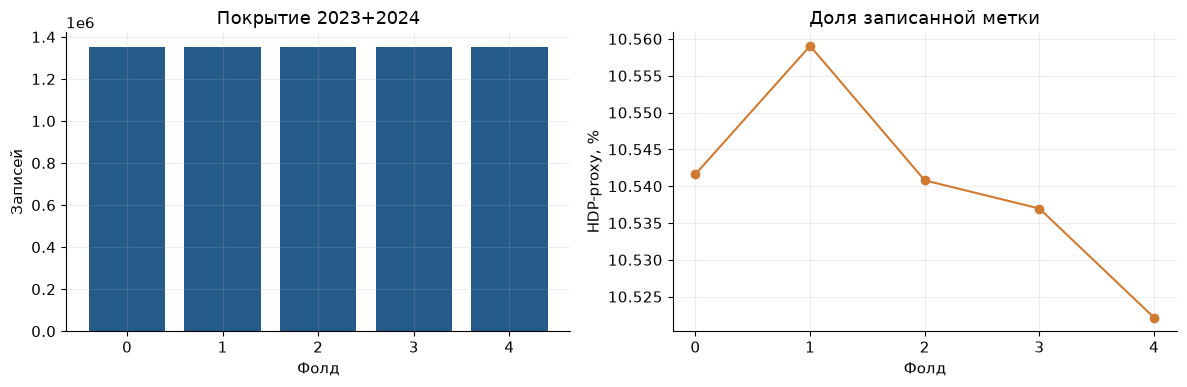

In [4]:
coverage=fold_metrics.loc[fold_metrics.model.eq("prevalence"),["fold","n","events","prevalence"]].sort_values("fold")
expected_rows=sum(item["eligible_singleton_rows"] for item in json.loads((OUT/"audit.json").read_text())["year_checks"].values())
assert coverage.fold.tolist()==list(range(5)) and coverage.n.sum()==expected_rows
display(coverage)
spread=fold_metrics.groupby("model")[["auroc","auprc","brier","log_loss"]].agg(["mean","std","min","max"])
display(spread.round(5))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(coverage.fold,coverage.n,color=BLUE)
axes[0].set(xlabel="Фолд",ylabel="Записей",title="Покрытие 2023+2024")
axes[1].plot(coverage.fold,100*coverage.prevalence,marker="o",color=ORANGE)
axes[1].set(xlabel="Фолд",ylabel="HDP-proxy, %",title="Доля записанной метки")
for ax in axes:ax.set_xticks(range(5))
plt.tight_layout();plt.show()

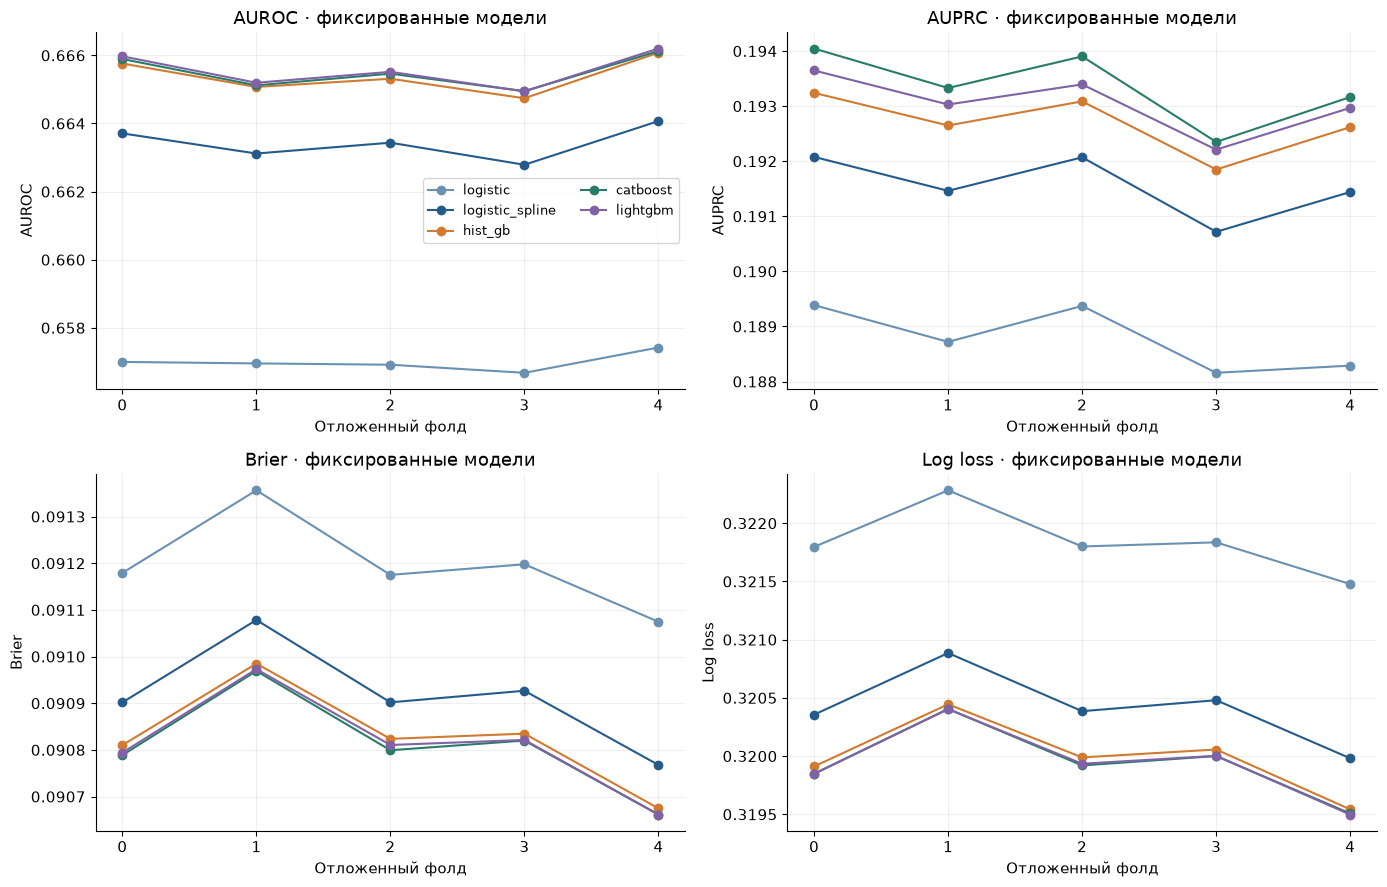

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, metric, ylabel in zip(axes.flat,["auroc","auprc","brier","log_loss"],["AUROC","AUPRC","Brier","Log loss"]):
    for name,color in [("logistic","#6A91B1"),*MODEL_PALETTE]:
        part=fold_metrics.loc[fold_metrics.model.eq(name)].sort_values("fold")
        ax.plot(part.fold,part[metric],marker="o",label=name,color=color)
    ax.set(xlabel="Отложенный фолд",ylabel=ylabel,title=f"{ylabel} · фиксированные модели")
    ax.set_xticks(range(5))
axes[0,0].legend(ncol=2,fontsize=9)
plt.tight_layout();plt.show()

Выше — оценки **фиксированных** конфигураций. Ниже параметры выбираются заново внутри каждого внешнего фолда; внешние прогнозы и их графики смотрите в 03. Для подбора только по 2023 и проверки переноса на 2024 используйте 06. Результаты каждого fit сохраняются, поэтому повторный запуск продолжает подтверждённые вычисления.

## Настроенные модели: вложенный подбор на общих фолдах

Для каждого внешнего фолда параметры и тип модели выбираются исключительно на остальных четырёх фолдах. Затем модели обучаются на этих четырёх фолдах и прогнозируют отложенный. Таким образом оценка в 03 относится к **процедуре выбора**, а не к параметрам одного готового экземпляра. Прогресс каждого кандидата и каждого фолда показывается при обучении; подтверждённые результаты сохраняются и повторно используются при перезапуске. Полный поиск на миллионах записей запускает пользователь.

In [6]:
import gc
from src.training.preeclampsia_cdc_tuning import GRID
from src.training.preeclampsia_cdc_nested import NESTED_DIR, run_nested_cv
from src.training.preeclampsia_cdc_final import FINAL_DIR, run_full_cohort_search, refit_full_cohort_best_models
print("Внутренних кандидатных fit:", 5 * 4 * sum(map(len, GRID.values())))
print("Внешних оценок моделей:", 5 * (len(MODEL_NAMES) + 1))
print("Финальных кандидатных fit:", 5 * sum(map(len, GRID.values())))

Внутренних кандидатных fit: 440
Внешних оценок моделей: 35
Финальных кандидатных fit: 110


In [7]:
inner_nested, outer_nested, choices_nested, oof_nested = run_nested_cv(resume=True)
expected_rows = sum(x["eligible_singleton_rows"] for x in json.loads((OUT / "audit.json").read_text())["year_checks"].values())
assert len(inner_nested) == 5 * 4 * sum(map(len, GRID.values()))
assert len(outer_nested) == 5 * (len(MODEL_NAMES) + 1)
assert len(oof_nested) == expected_rows
assert oof_nested.groupby(["source_year", "fold"]).size().gt(0).all()
nested_n, nested_events = len(oof_nested), int(oof_nested.label.sum())
print("Внешние OOF-прогнозы:", f"{nested_n:,}")
display(choices_nested)
del inner_nested, outer_nested, choices_nested, oof_nested
gc.collect()

Nested CV: inner grid:   0%|          | 0/440 [00:00<?, ?fit/s]

Nested CV: outer refits:   0%|          | 0/30 [00:00<?, ?model/s]

Outer 0 / inner 1: hist_gb 422a30:   0%|          | 0/100 [00:00<?, ?tree/s]

Outer 0 / inner 1: hist_gb 8b9b7a:   0%|          | 0/100 [00:00<?, ?tree/s]

Outer 0 / inner 1: hist_gb 2dc832:   0%|          | 0/100 [00:00<?, ?tree/s]

Outer 0 / inner 1: hist_gb 28fde1:   0%|          | 0/100 [00:00<?, ?tree/s]

... (250 outputs left out)

Outer 4 selected: lightgbm:   0%|          | 0/300 [00:00<?, ?tree/s]

Внешние OOF-прогнозы: 6,763,850


,outer_fold,overall_winner,prevalence_candidate_id,logistic_candidate_id,logistic_spline_candidate_id,hist_gb_candidate_id,catboost_candidate_id,lightgbm_candidate_id
0,0,catboost,7e05976576b2,98aeddc3133d,247cce42f0e8,8b9b7a3ca540,08d1effab5f7,c50553e3d039
1,1,catboost,7e05976576b2,98aeddc3133d,247cce42f0e8,8b9b7a3ca540,97a167526785,c50553e3d039
2,2,catboost,7e05976576b2,98aeddc3133d,247cce42f0e8,8b9b7a3ca540,08d1effab5f7,c50553e3d039
3,3,catboost,7e05976576b2,98aeddc3133d,247cce42f0e8,28fde1366938,08d1effab5f7,1f7e1bceccdd
4,4,catboost,7e05976576b2,98aeddc3133d,247cce42f0e8,8b9b7a3ca540,97a167526785,c50553e3d039


32

## Выбор финальных параметров и обучение на всех записях

После завершения вложенной оценки проводится **отдельный** пятифолдовый поиск на всей когорте 2023+2024. Он выбирает параметры каждой модели и общий тип по взвешенному `log loss`. Эти поисковые метрики оптимистичны после выбора; внешние метрики вложенного поиска смотрите в 03. Итоговые модели обучаются на всех записях и не оцениваются на этих же строках.

In [9]:
final_folds, final_summary, final_best = run_full_cohort_search(resume=True)
assert len(final_folds) == 5 * sum(map(len, GRID.values()))
assert final_best["development_n"] == nested_n
assert final_best["development_events"] == nested_events
print("Победитель полного подбора:", final_best["overall_winner"])
display(final_summary.round(5))
display(pd.DataFrame(final_best["best_by_model"]).T)
del final_folds
gc.collect()

2023+2024 final model grid:   0%|          | 0/110 [00:00<?, ?fit/s]

Final grid fold 0: lightgbm c50553:   0%|          | 0/300 [00:00<?, ?tree/s]

Final grid fold 1: hist_gb 422a30:   0%|          | 0/100 [00:00<?, ?tree/s]

Final grid fold 1: hist_gb 8b9b7a:   0%|          | 0/100 [00:00<?, ?tree/s]

Final grid fold 1: hist_gb 2dc832:   0%|          | 0/100 [00:00<?, ?tree/s]

Final grid fold 1: hist_gb 28fde1:   0%|          | 0/100 [00:00<?, ?tree/s]

... (44 outputs left out)

Победитель полного подбора: catboost


,model,candidate_id,params_json,n_oof,events_oof,cv_log_loss,cv_brier,auroc_fold_mean,auprc_fold_mean,log_loss_fold_sd,fit_seconds_total
0,catboost,97a167526785,"{""depth"": 5, ""l2_leaf_reg"": 3.0}",6763850,712918,0.31993,0.09081,0.66552,0.19337,0.00032,264.34002
1,catboost,08d1effab5f7,"{""depth"": 5, ""l2_leaf_reg"": 8.0}",6763850,712918,0.31994,0.09081,0.66551,0.19336,0.00032,273.37759
2,catboost,baba1e1a2640,"{""depth"": 4, ""l2_leaf_reg"": 8.0}",6763850,712918,0.31996,0.09081,0.66539,0.19328,0.00033,244.11921
3,catboost,3970c5f1f343,"{""depth"": 4, ""l2_leaf_reg"": 3.0}",6763850,712918,0.31997,0.09081,0.66539,0.19326,0.00033,237.51932
4,hist_gb,8b9b7a3ca540,"{""l2_regularization"": 1.0, ""max_leaf_nodes"": 15}",6763850,712918,0.31999,0.09083,0.66539,0.19270,0.00032,91.26088
5,hist_gb,28fde1366938,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 15}",6763850,712918,0.31999,0.09083,0.66539,0.19269,0.00032,92.16375
6,hist_gb,2dc832909c75,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 7}",6763850,712918,0.32012,0.09085,0.66486,0.19225,0.00032,72.88068
7,hist_gb,422a3066c0f1,"{""l2_regularization"": 1.0, ""max_leaf_nodes"": 7}",6763850,712918,0.32013,0.09085,0.66485,0.19224,0.00032,70.72931
8,lightgbm,c50553e3d039,"{""min_child_samples"": 500, ""num_leaves"": 15}",6763850,712918,0.31994,0.09081,0.66557,0.19306,0.00032,79.23552
9,lightgbm,1f7e1bceccdd,"{""min_child_samples"": 200, ""num_leaves"": 15}",6763850,712918,0.31994,0.09081,0.66557,0.19305,0.00032,80.00897


,candidate_id,params,cv_log_loss
prevalence,7e05976576b2,{},0.336791
logistic,98aeddc3133d,{'C': 10.0},0.321839
logistic_spline,247cce42f0e8,"{'C': 3.0, 'n_knots': 5}",0.320418
hist_gb,8b9b7a3ca540,"{'l2_regularization': 1.0, 'max_leaf_nodes': 15}",0.319989
catboost,97a167526785,"{'depth': 5, 'l2_leaf_reg': 3.0}",0.319933
lightgbm,c50553e3d039,"{'min_child_samples': 500, 'num_leaves': 15}",0.319936


49

In [10]:
global_manifest = refit_full_cohort_best_models(resume=True)
assert global_manifest["overall_winner"] == final_best["overall_winner"]
print("Итоговый победитель:", global_manifest["overall_winner"])
display(pd.DataFrame([{"model": name, "artifact": path} for name, path in global_manifest["artifacts"].items()]))

Final full-cohort refit:   0%|          | 0/5 [00:00<?, ?model/s]

Global full-cohort: hist_gb:   0%|          | 0/100 [00:00<?, ?tree/s]

Global full-cohort: catboost:   0%|          | 0/300 [00:00<?, ?tree/s]

Global full-cohort: lightgbm:   0%|          | 0/300 [00:00<?, ?tree/s]

Итоговый победитель: catboost


,model,artifact
0,prevalence,/Users/nick/Desktop/projects/femfedora/models/...
1,logistic,/Users/nick/Desktop/projects/femfedora/models/...
2,logistic_spline,/Users/nick/Desktop/projects/femfedora/models/...
3,hist_gb,/Users/nick/Desktop/projects/femfedora/models/...
4,catboost,/Users/nick/Desktop/projects/femfedora/models/...
5,lightgbm,/Users/nick/Desktop/projects/femfedora/models/...
